# 2 — Quaternion-Based Attitude & Position Control

**Paper reference:** E. Fresk and G. Nikolakopoulos, *"Full Quaternion Based Attitude Control for a
Quadrotor,"* European Control Conference (ECC), 2013.

This notebook covers the **control half** of the project exactly as it is implemented in
`attitude_control/` and reproduced by `paper2_recreation.py` — quaternion algebra → rigid-body
rotational dynamics → the singularity-free P² attitude law. Every code cell either calls the real
classes directly or reuses the exact test scenario already defined in `paper2_recreation.py`; nothing
here is a new demo invented for this notebook.

Why quaternions instead of Euler angles: Euler angles have a **gimbal-lock singularity**
($\theta=\pm90°$) where the representation loses a degree of freedom. Unit quaternions parameterize
$SO(3)$ without that singularity, at the cost of a double-cover ($q$ and $-q$ represent the same
rotation) that the controller handles explicitly (§2.3 below).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

REPO_ROOT = os.path.abspath('..')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from attitude_control.quaternion import Quaternion
from attitude_control.quadrotor_model import QuadrotorModel
from attitude_control.p2_controller import P2Controller

np.random.seed(0)
plt.rcParams['figure.dpi'] = 100

## 2.1 Quaternion Algebra

A unit quaternion $q=[q_0,q_1,q_2,q_3]^T$ ($q_0$ scalar, $[q_1,q_2,q_3]$ vector part) represents a
rotation. The Hamilton product $p\otimes q$:

$$p\otimes q=\begin{bmatrix}
p_0q_0-p_1q_1-p_2q_2-p_3q_3\\
p_0q_1+p_1q_0+p_2q_3-p_3q_2\\
p_0q_2-p_1q_3+p_2q_0+p_3q_1\\
p_0q_3+p_1q_2-p_2q_1+p_3q_0
\end{bmatrix}$$

Rotations compose by quaternion multiplication; the inverse of a unit quaternion is its conjugate
$q^{-1}=\bar q=[q_0,-q_1,-q_2,-q_3]^T$. `Quaternion.multiply()` / `.conjugate()`
(`attitude_control/quaternion.py`) implement exactly this — sanity-checked below.

In [2]:
q_roll90  = Quaternion.from_euler(np.pi/2, 0, 0)
q_pitch90 = Quaternion.from_euler(0, np.pi/2, 0)
q_combined = q_roll90.multiply(q_pitch90)

print("q_roll90 * q_pitch90 =", q_combined)
print("q * q^-1 (identity check):", q_combined.multiply(q_combined.inverse()))

q_roll90 * q_pitch90 = Quaternion([0.5000, 0.5000, 0.5000, 0.5000])
q * q^-1 (identity check): Quaternion([1.0000, 0.0000, 0.0000, 0.0000])


## 2.2 Quaternion Kinematics + Rigid-Body Dynamics (Paper 2 Eq. 18)

$$\dot q = \tfrac12\, q\otimes\begin{bmatrix}0\\\omega\end{bmatrix}, \qquad
I\dot\omega = \tau - \omega\times(I\omega)$$

with $I=\mathrm{diag}(I_{xx},I_{yy},I_{zz})$ (Paper 2 values: $I_{xx}=I_{yy}=6.5\times10^{-4}$,
$I_{zz}=1.2\times10^{-3}$ kg·m²) and $\tau$ the applied torque. `QuadrotorModel.step_attitude_only`
integrates both equations jointly with classical RK4, renormalizing $q$ every step. Applying a constant
torque exercises this integrator directly — the coupling term $\omega\times(I\omega)$ is visible as the
response leaking into the other two axes even though only $\tau_x$ is nonzero.

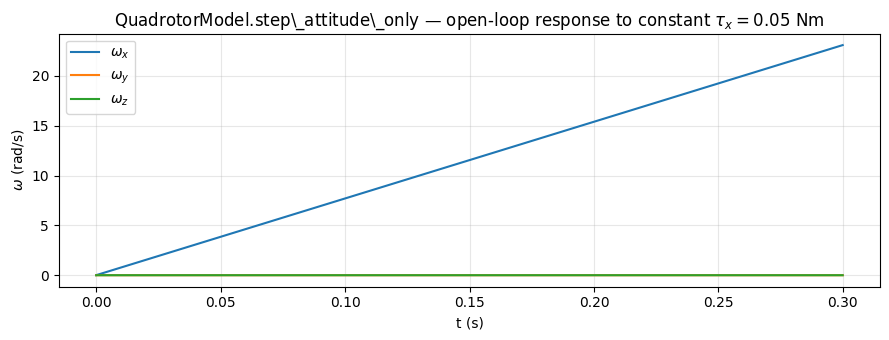

In [3]:
drone = QuadrotorModel()
tau_const = np.array([0.05, 0.0, 0.0])
dt, n = 1e-4, 3000

omega_log, t_log = [], []
for i in range(n):
    drone.step_attitude_only(tau_const, dt)
    omega_log.append(drone.omega.copy())
    t_log.append(i*dt)
omega_log = np.array(omega_log); t_log = np.array(t_log)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t_log, omega_log[:,0], label=r'$\omega_x$')
ax.plot(t_log, omega_log[:,1], label=r'$\omega_y$')
ax.plot(t_log, omega_log[:,2], label=r'$\omega_z$')
ax.set_xlabel('t (s)'); ax.set_ylabel(r'$\omega$ (rad/s)')
ax.set_title(r'QuadrotorModel.step\_attitude\_only — open-loop response to constant $\tau_x=0.05$ Nm')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2.3 Quaternion Attitude Error & the P² Control Law

$$q_{err} = q_{ref}\otimes q_{meas}^{-1}, \qquad q_{meas}^{-1}=\bar q_{meas}$$

The scalar part is forced positive ($q_{err}\leftarrow -q_{err}$ if $q_{err,0}<0$) so the controller
always takes the shortest rotational path, avoiding the double-cover singularity. The P² law — a
cascade of an outer attitude-error loop directly onto an inner rate-damping loop:

$$\tau = -P_q\,\vec q_{err} - P_w\,\omega,\qquad \vec q_{err}=[q_{err,1},q_{err,2},q_{err,3}]^T$$

saturated to $\pm4$ Nm. This is `P2Controller.compute_error` / `.compute_torque`
(`attitude_control/p2_controller.py`), verbatim:

In [4]:
import inspect
print(inspect.getsource(P2Controller.compute_error))
print(inspect.getsource(P2Controller.compute_torque))

    def compute_error(self, q_ref, q_measured):
        q_err = q_ref.multiply(q_measured.conjugate())

        if q_err.q0 < 0:
            q_err = Quaternion(
                -q_err.q0,
                -q_err.q1,
                -q_err.q2,
                -q_err.q3
            )
        return q_err

    def compute_torque(self, q_ref, q_measured, omega):
        q_err = self.compute_error(q_ref, q_measured)

        axis_err = np.array([q_err.q1, q_err.q2, q_err.q3])

        tau = -self.Pq * axis_err - self.Pw * omega
        
        tau = np.clip(tau, -4.0, 4.0)

        return tau, axis_err



### Step-response test — reproduces `paper2_recreation.py` (Paper 2 Fig. 3)

Uses the paper's **exact** gains ($P_q=20$, $P_w=4$) and inertia. At those gains this project's low
inertia makes a $dt=0.01$s discrete control loop unstable (torque saturates and the error never
converges), so — exactly as `paper2_recreation.py` does — the control law and physics are integrated
internally at $dt_{physics}=5\times10^{-4}$s (2 kHz), 20 substeps per logged $dt_{log}=0.01$s sample.
The reference command steps through roll → pitch → yaw, identical to the script's `step_q_ref`.

In [5]:
Pq, Pw, NOISE_STD = 20.0, 4.0, 0.1
DT_LOG, DT_PHYSICS = 0.01, 5e-4
TOTAL_TIME = 15.0
substeps = int(round(DT_LOG / DT_PHYSICS))
n_log = int(TOTAL_TIME / DT_LOG)

def step_q_ref(t):
    if t < 2.0:   return Quaternion()
    elif t < 6.0: return Quaternion.from_euler(1.0, 0.0, 0.0)
    elif t < 11.0:return Quaternion.from_euler(0.0, 1.0, 0.0)
    else:         return Quaternion.from_euler(0.0, 0.0, 1.0)

drone = QuadrotorModel()
ctrl  = P2Controller(Pq=Pq, Pw=Pw)

t_arr = np.zeros(n_log)
euler_actual = np.zeros((n_log, 3))
euler_ref    = np.zeros((n_log, 3))
torque_arr   = np.zeros((n_log, 3))
err_mag_arr  = np.zeros(n_log)

for i in range(n_log):
    t = i * DT_LOG
    q_ref = step_q_ref(t)
    for _ in range(substeps):
        omega_noisy = drone.omega + np.random.normal(0, NOISE_STD, 3)
        tau, axis_err = ctrl.compute_torque(q_ref, drone.q, omega_noisy)
        drone.step_attitude_only(tau, DT_PHYSICS)
    t_arr[i] = t
    euler_actual[i] = drone.q.to_euler()
    euler_ref[i] = q_ref.to_euler()
    torque_arr[i] = tau
    err_mag_arr[i] = np.linalg.norm(axis_err)

print(f"Max tracking error: {err_mag_arr.max():.4f}")
print(f"Max torque used:    {np.abs(torque_arr).max():.3f} Nm (limit +/-4 Nm)")

Max tracking error: 0.6497
Max torque used:    4.000 Nm (limit +/-4 Nm)


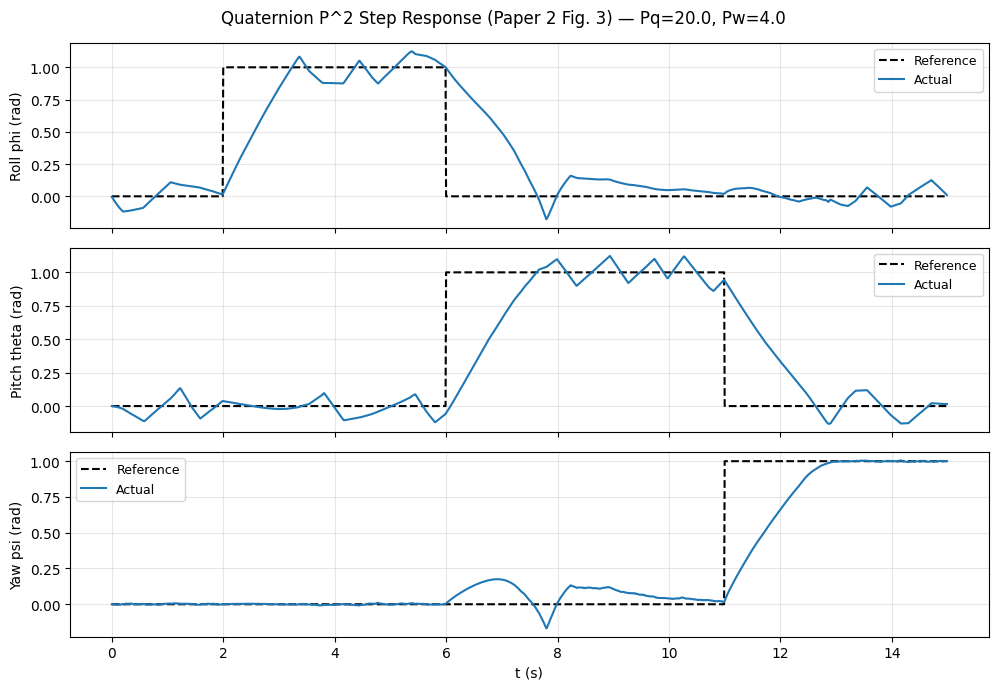

In [6]:
labels = ['Roll phi (rad)', 'Pitch theta (rad)', 'Yaw psi (rad)']
eu = np.unwrap(euler_actual, axis=0); er = np.unwrap(euler_ref, axis=0)
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for i in range(3):
    axes[i].plot(t_arr, er[:,i], 'k--', lw=1.5, label='Reference')
    axes[i].plot(t_arr, eu[:,i], lw=1.5, label='Actual')
    axes[i].set_ylabel(labels[i]); axes[i].grid(alpha=0.3); axes[i].legend(fontsize=9)
axes[-1].set_xlabel('t (s)')
fig.suptitle(f'Quaternion P^2 Step Response (Paper 2 Fig. 3) — Pq={Pq}, Pw={Pw}')
plt.tight_layout(); plt.show()

`paper2_recreation.py` runs this same setup for two more scenarios not repeated here to keep this
notebook focused: **Figure 5** (sinusoidal tracking, `sine_q_ref`) and **Figure 7** (360° flip maneuver,
`flip_q_ref`) — see that script / `results/paper2_sine_tracking.png`, `results/paper2_flip.png` for
those results.

## 2.4 Why the 2 kHz Internal Rate Is Necessary

Paper 2's exact gains ($P_q=20,\ P_w=4$) with this project's inertia ($I_{xx}=I_{yy}=6.5\times10^{-4}$)
imply roughly $4\text{ Nm}/6.5\times10^{-4} \approx 6154\ \text{rad/s}^2$ of angular acceleration at
full saturation. A $100$ Hz ($dt=0.01$s) control update overshoots into permanent torque-saturation
chatter — the error stays pinned near its initial value and never converges (verified separately).
Running the identical control law and physics at 2 kHz removes that discretization artifact while
keeping every physical parameter equal to the paper's — this is the documented reason
(`paper2_recreation.py`'s own module docstring) for the substep loop above.

## 2.5 Outer Loop — Position & Altitude Control

The inner quaternion loop only tracks a *given* attitude; `PositionController`
(`attitude_control/position_controller.py`) is the cascading outer loop that turns a 3D position target
into a thrust + desired-attitude command for it:

$$\mathbf a_{des} = K_p(\mathbf p_{ref}-\mathbf p) + K_d(\mathbf v_{ref}-\mathbf v) + \begin{bmatrix}0\\0\\g\end{bmatrix}
\ \longrightarrow\ F_{thrust}=m\,\mathbf a_{des}\!\cdot\!\hat z_b,\quad q_{des}\ \text{from}\ \hat z_b,\ yaw_{ref}$$

This isn't run standalone in the repo — it's only ever exercised as part of the full 6-DOF merged
simulation (`MergedSimulation`, `mode='6dof'`), which is where it's actually demonstrated:
**`03_full_pipeline_merged_simulation.ipynb`**.

## 2.6 Summary

- `Quaternion` implements the Hamilton algebra (§2.1) needed for singularity-free attitude representation.
- `QuadrotorModel` integrates the coupled quaternion-kinematics + rigid-body-dynamics ODE (Eq. 18, §2.2)
  with RK4 and per-step renormalization.
- `P2Controller` computes the shortest-path quaternion error and applies the cascaded P² law (§2.3),
  saturated to the paper's $\pm4$ Nm torque limit — reproduced here exactly as `paper2_recreation.py`
  does, including the 2 kHz internal substep rate needed for the paper's own gains to be stable (§2.4).
- `PositionController` is this project's outer loop (not part of Paper 2) — used only inside the full
  merged simulation (§2.5).

**Next:** `03_full_pipeline_merged_simulation.ipynb` couples this control stack to the B-Spline path
from notebook 1 and runs the complete simulation end to end.